# Tiền xử lý và sáu nhãn tương lai
Không điền dữ liệu nguồn khi không có missing. Ridge scale trong từng tập train. Nhãn tương lai chỉ phục vụ học và chấm điểm offline.

In [1]:
from pathlib import Path
import sys,json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/appliances').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from src.appliances.config import RELEASE,MODEL_DIR,HORIZONS,BOUNDARIES
from src.appliances.data import load_data
from src.appliances.features import supervised,split_rows,make_features,feature_columns
raw,audit=load_data()
rows,columns=supervised(raw)
parts,counts=split_rows(rows)
def read_json(name):
    return json.loads((RELEASE/name).read_text(encoding='utf-8'))


train          11988
validation      2010
calibration     2010
test            2695
Name: usable_rows, dtype: int64

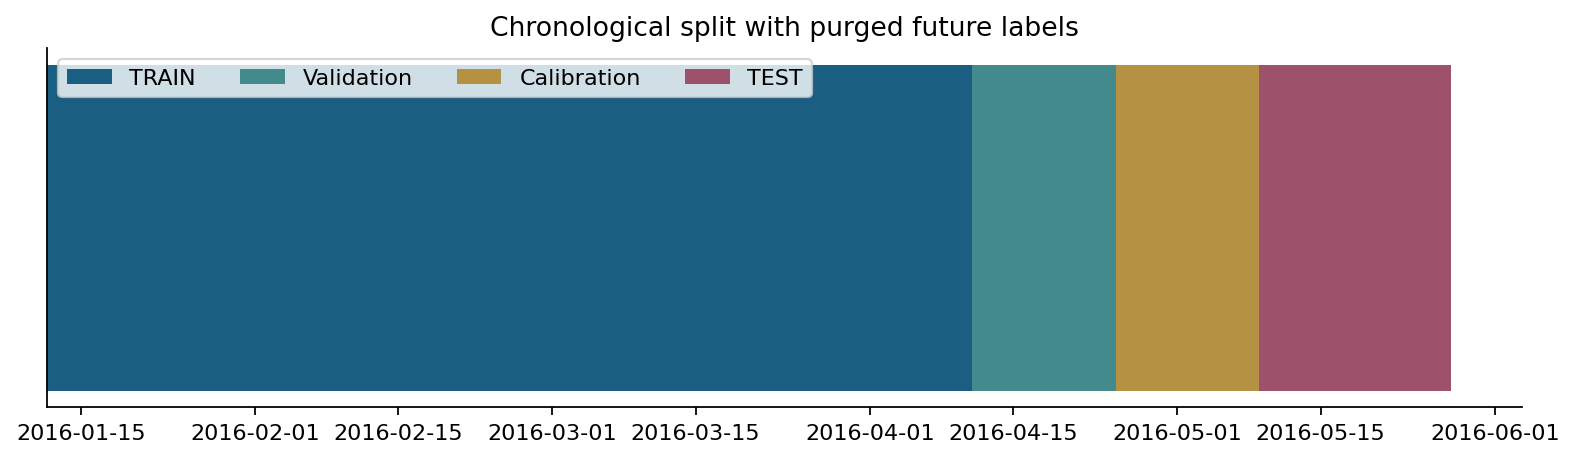

,feature,group
0,energy_lag_0,G0 + G1
1,energy_lag_1,G0 + G1
2,energy_lag_2,G0 + G1
3,energy_lag_3,G0 + G1
4,energy_lag_6,G0 + G1
5,energy_lag_144,G0 + G1
6,energy_lag_1008,G0 + G1
7,sum_1h,G0 + G1
8,mean_4h,G0 + G1
9,std_4h,G0 + G1


In [2]:
display(pd.Series(counts,name="usable_rows"))
display(Image(filename=str(RELEASE/"figures/03_split.png")))
display(pd.DataFrame({"feature":columns,"group":["G0 + G1" if c in feature_columns(rows[columns],"G0") else "G1 only" for c in columns]}))

## Các phép tính
Một giờ gồm 6 bản đo. Một ngày gồm 144 bản đo. Một tuần gồm 1.008 bản đo. Rolling kết thúc tại thời điểm phát dự báo. Cảm biến G1 trễ thêm một khoảng hoàn tất. Giờ và thứ dùng sin/cos, cuối tuần là nhị phân.

In [3]:
i=1500
print("Issue",raw.timestamp.iloc[i])
measured=raw.iloc[i+1:i+7][["timestamp","Appliances","energy_kWh"]]
display(measured)
print("Tổng thực tế giờ tới", measured.energy_kWh.sum(), "kWh")
print("Tổng nhãn trong pipeline", rows.actual_hour_kWh.iloc[i])
assert np.isclose(measured.energy_kWh.sum(), rows.actual_hour_kWh.iloc[i])

Issue 2016-01-22 03:00:00


,timestamp,Appliances,energy_kWh
1501,2016-01-22 03:10:00,30,0.03
1502,2016-01-22 03:20:00,40,0.04
1503,2016-01-22 03:30:00,50,0.05
1504,2016-01-22 03:40:00,40,0.04
1505,2016-01-22 03:50:00,50,0.05
1506,2016-01-22 04:00:00,30,0.03


Tổng thực tế giờ tới 0.24000000000000002 kWh
Tổng nhãn trong pipeline 0.24000000000000002


In [4]:
changed=raw.copy()
changed.loc[i+1,"energy_kWh"] += 1 # Chỉ là phép thử nhân quả trên bản sao, không ghi vào dataset
np.testing.assert_array_equal(make_features(raw).iloc[i],make_features(changed).iloc[i])
print("PASS: sửa tương lai không làm đổi feature hiện tại")

PASS: sửa tương lai không làm đổi feature hiện tại


## Chia tập
TRAIN đến 10/04, validation 11–24/04, calibration 25/04–08/05, TEST 09–27/05/2016. Mỗi ranh giới loại 6 origin có nhãn đi sang tập tiếp theo. Không học scaler bằng TEST.